# 01 · Data collection, cleaning & exploratory analysis

**Goal.** Obtain real Sri Lankan dengue surveillance data and matching weather, clean it, and
understand its structure before modelling.

* **Dengue:** `srilanka_weekly_data` from the R package **denguedatahub** (weekly cases for each of the
  26 Regional Director of Health Services (RDHS) areas, compiled from the Epidemiology Unit, Ministry of Health, Sri Lanka).
* **Weather:** **Open-Meteo Historical Weather API** (ERA5 reanalysis): daily rainfall, mean
  temperature and mean relative humidity at each district centre.

All logic lives in `src/data.py`; this notebook calls it and explores the results.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

## 1. Download & clean
`build_clean_datasets()` downloads the `.rda` file from GitHub (read with `pyreadr`), exports it
unchanged to `data/raw/dengue.csv`, cleans it, and fetches/caches weather (`data/raw/weather.csv`).
Re-running uses the cached files, so the API is only called once.

In [2]:
from src import data
dengue = data.build_clean_datasets()
raw = pd.read_csv(config.DENGUE_RAW_CSV)
print("raw rows:", len(raw), "| clean rows:", len(dengue))
print("period:", dengue.start_date.min().date(), "->", dengue.end_date.max().date())
print("regions:", dengue.district.nunique())
dengue.head()

raw rows: 26753 | clean rows: 26753
period: 2006-12-23 -> 2026-09-13
regions: 26


,district,start_date,end_date,year,week,cases,missing_report
0,Ampara,2006-12-23,2006-12-29,2006,52,0.0,False
1,Ampara,2006-12-30,2007-01-05,2007,1,0.0,False
2,Ampara,2007-01-06,2007-01-12,2007,2,0.0,False
3,Ampara,2007-01-13,2007-01-19,2007,3,0.0,False
4,Ampara,2007-01-20,2007-01-26,2007,4,0.0,False


### Data-quality checks and the cleaning decisions they led to
1. **Spelling variants** (`Hambanthota`, `NuwaraEliya`, `Kalmune`) → standard names. *Kalmunai* is a separate
   RDHS area inside Ampara district; we keep it as its own region but use Ampara's coordinates for weather.
2. **Two date formats** (`12/23/2006` and `2026-09-07`) → parsed with `format="mixed"`.
3. **Inconsistent year/week labels at New Year** → year and week are rebuilt from the reporting week's mid-date (see below).

In [3]:
print("Raw spellings fixed:", data.NAME_FIXES)
print("Raw date formats: slash =", raw["start.date"].str.contains("/").sum(), "| ISO =", raw["start.date"].str.contains("-").sum())

# Example of the label problem: raw labels vs our rebuilt calendar around New Year
ex = raw[(raw.district == "Colombo") & raw["start.date"].isin(["12/16/2023", "12/23/2023", "12/13/2025", "12/20/2025", "12/29/2025"])]
fixed = dengue[(dengue.district == "Colombo") & dengue.start_date.isin(pd.to_datetime(ex["start.date"], format="mixed"))]
pd.concat([ex[["start.date", "year", "week"]].reset_index(drop=True).add_prefix("raw_"),
           fixed[["year", "week"]].reset_index(drop=True).add_prefix("clean_")], axis=1)

Raw spellings fixed: {'Hambanthota': 'Hambantota', 'NuwaraEliya': 'Nuwara Eliya', 'Kalmune': 'Kalmunai'}
Raw date formats: slash = 26311 | ISO = 442


,raw_start.date,raw_year,raw_week,clean_year,clean_week
0,12/16/2023,2023.0,51.0,2023,51
1,12/23/2023,2024.0,1.0,2023,52
2,12/13/2025,2025.0,52.0,2025,50
3,12/20/2025,2026.0,53.0,2025,51
4,12/29/2025,2026.0,1.0,2026,1


### Zeros that are really *missing reports*
Some zeros are not "no dengue" but "no report". Two patterns stand out:
* a region reporting **0 for a whole year** while reporting cases in other years
  (Kilinochchi & Mullaitivu 2007-2009, the final phase of the civil war; Monaragala 2020);
* a **single week where ≥ 20 of 26 regions report 0 while neighbouring weeks have only a few**, a
  national reporting gap. (Mid-2012 also has a week with 20 zero-reporting regions, but its neighbours
  have 13–19, so it is normal low season for small regions and is *not* flagged; see the evidence below.)

`flag_missing_reports()` sets these to `NaN` with `missing_report = True`. We do **not** impute
them (that would invent data); any feature row that needs them is dropped in notebook 02.

In [4]:
flagged = dengue[dengue.missing_report]
print("flagged district-weeks:", len(flagged), f"({100*len(flagged)/len(dengue):.2f}% of rows)")
print(flagged.groupby(["district", "year"]).size().rename("weeks").to_string())

# Evidence for the national gap weeks: number of zero-reporting regions around them
zeros = raw.assign(sd=pd.to_datetime(raw["start.date"], format="mixed")).groupby("sd").cases.apply(lambda s: (s == 0).sum())
for gap in ["2012-06-16", "2022-09-10"]:
    g = pd.Timestamp(gap)
    print(f"\nregions reporting 0 around {gap}:", zeros[g - pd.Timedelta(weeks=3): g + pd.Timedelta(weeks=3)].to_dict())

flagged district-weeks: 389 (1.45% of rows)
district      year
Ampara        2022     1
Anuradhapura  2022     1
Badulla       2022     1
Batticaloa    2022     1
Galle         2022     1
Hambantota    2022     1
Jaffna        2022     1
Kalmunai      2022     1
Kandy         2022     1
Kegalle       2022     1
Kilinochchi   2007    52
              2008    53
              2009    52
              2022     1
Kurunegala    2022     1
Mannar        2022     1
Matale        2022     1
Matara        2022     1
Monaragala    2020    52
              2022     1
Mullaitivu    2007    52
              2008    53
              2009    52
              2022     1
Nuwara Eliya  2022     1
Polonnaruwa   2022     1
Puttalam      2022     1
Ratnapura     2022     1
Trincomalee   2022     1
Vavuniya      2022     1

regions reporting 0 around 2012-06-16: {Timestamp('2012-05-26 00:00:00'): 19, Timestamp('2012-06-02 00:00:00'): 17, Timestamp('2012-06-09 00:00:00'): 18, Timestamp('2012-06-16 00:00:00')

In [5]:
print("missing values:\n", dengue.isna().sum().to_dict())
print("duplicate district-weeks:", dengue.duplicated(["district", "start_date"]).sum())
gaps = dengue[dengue.district == "Colombo"].start_date.diff().dt.days.value_counts().sort_index()
print("gap between consecutive reporting weeks (days -> count):", gaps.to_dict())
dengue.cases.describe().round(1)

missing values:
 {'district': 0, 'start_date': 0, 'end_date': 0, 'year': 0, 'week': 0, 'cases': 389, 'missing_report': 0}
duplicate district-weeks: 0
gap between consecutive reporting weeks (days -> count): {6.0: 1, 7.0: 1025, 8.0: 1, 9.0: 1}


count    26364.0
mean        34.1
std         87.3
min          0.0
25%          2.0
50%         10.0
75%         31.0
max       2631.0
Name: cases, dtype: float64

## 2. National trend

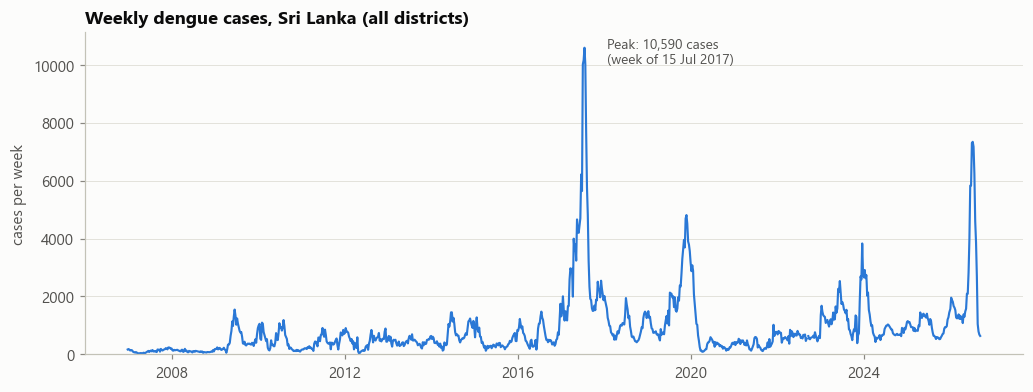

Annual totals:
 year
2006       167
2007      6019
2008      5715
2009     26552
2010     25006
2011     21647
2012     23527
2013     23021
2014     35650
2015     22180
2016     34355
2017    174687
2018     51321
2019     97949
2020     29404
2021     19862
2022     31674
2023     73678
2024     52873
2025     49230
2026     94033


In [6]:
nat = data.national_weekly(dengue)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(nat.index, nat.values, color=viz.SERIES[0], lw=1.4)
peak = nat.idxmax()
ax.annotate(f"Peak: {int(nat.max()):,} cases\n(week of {peak:%d %b %Y})", xy=(peak, nat.max()),
            xytext=(15, -10), textcoords="offset points", color=viz.INK_2, fontsize=9)
ax.set_title("Weekly dengue cases, Sri Lanka (all districts)")
ax.set_ylabel("cases per week"); ax.set_ylim(0)
viz.save(fig, "eda_national_trend"); plt.show()

annual = dengue.groupby("year").cases.sum().astype(int)   # 2006 = 1 week only; 2026 = up to 13 Sep
print("Annual totals:\n", annual.to_string())

## 3. Which districts carry the burden?

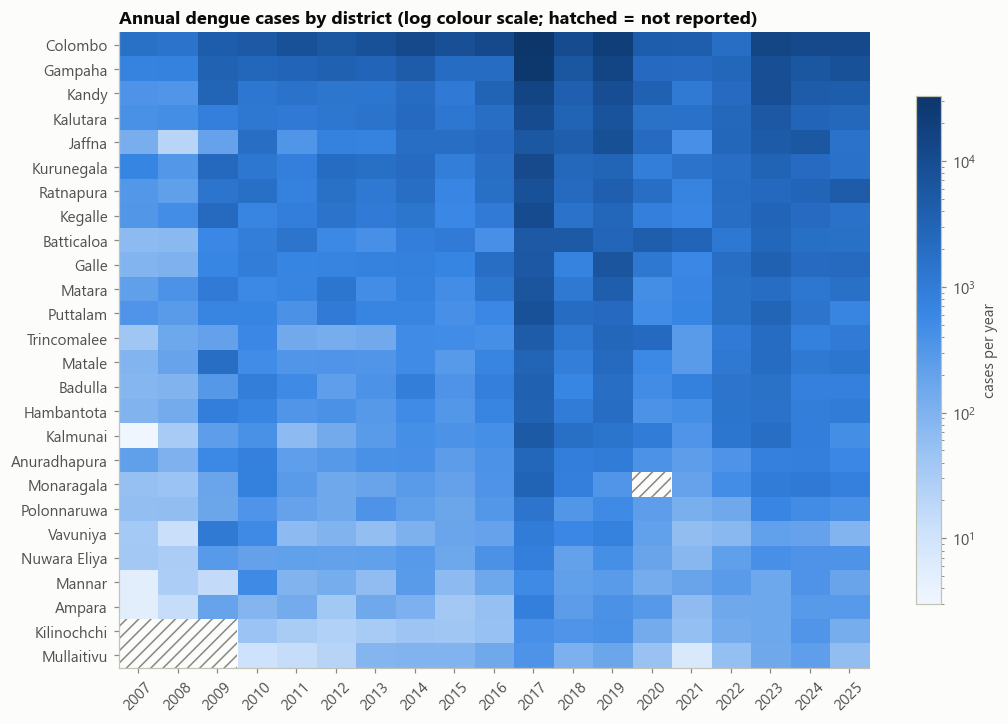

Share of all 2007-2025 cases (%):
 district
Colombo       21.8
Gampaha       12.8
Kandy          8.3
Kalutara       6.0
Jaffna         5.6
Kurunegala     5.2
Ratnapura      4.9
Kegalle        4.2
Batticaloa     4.1
Galle          3.9


In [7]:
from matplotlib.colors import LogNorm
full_years = dengue[dengue.year.between(2007, 2025)]          # complete calendar years only
# min_count=1 keeps a year that was never reported as NaN instead of a misleading 0
heat = full_years.groupby(["district", "year"]).cases.sum(min_count=1).unstack()
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 7.5))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", viz.SEQ_BLUE)
im = ax.imshow(np.ma.masked_invalid(heat.values), aspect="auto", cmap=cmap,
               norm=LogNorm(vmin=max(np.nanmin(heat.values), 1), vmax=np.nanmax(heat.values)))
# Hatch the not-reported cells so they cannot be mistaken for "low"
for (i, j) in zip(*np.where(heat.isna().values)):
    ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor=viz.SURFACE, edgecolor=viz.MUTED, hatch="///", lw=0))
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=45); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False); ax.set_title("Annual dengue cases by district (log colour scale; hatched = not reported)")
fig.colorbar(im, ax=ax, label="cases per year", shrink=0.8)
viz.save(fig, "eda_district_heatmap"); plt.show()

share = (heat.sum(axis=1) / np.nansum(heat.values) * 100).round(1)
print("Share of all 2007-2025 cases (%):\n", share.head(10).to_string())

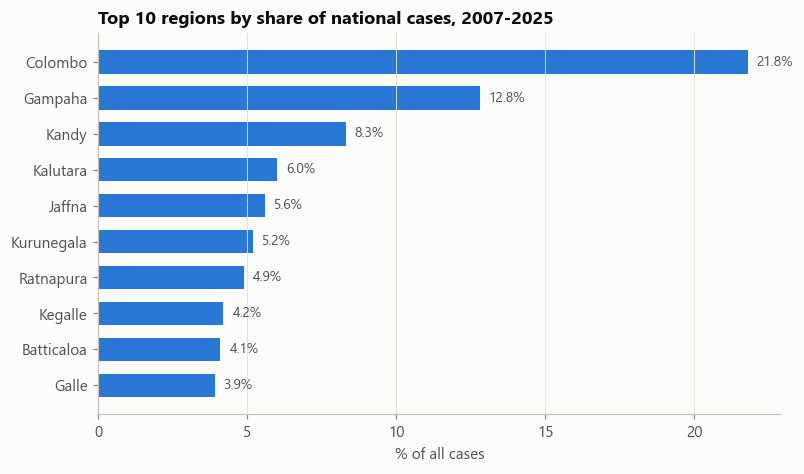

In [8]:
top10 = share.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index, top10.values, color=viz.SERIES[0], height=0.65)
for i, v in enumerate(top10.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", color=viz.INK_2, fontsize=9)
ax.set_title("Top 10 regions by share of national cases, 2007-2025")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.set_xlabel("% of all cases")
viz.save(fig, "eda_top10_districts"); plt.show()

## 4. Seasonality
Two separate panels (one y-axis each): typical cases by week of year, and typical rainfall by week of year.
Sri Lanka has two monsoons, the South-West (May–Sep) and North-East (Oct–Jan), so we expect two case peaks.

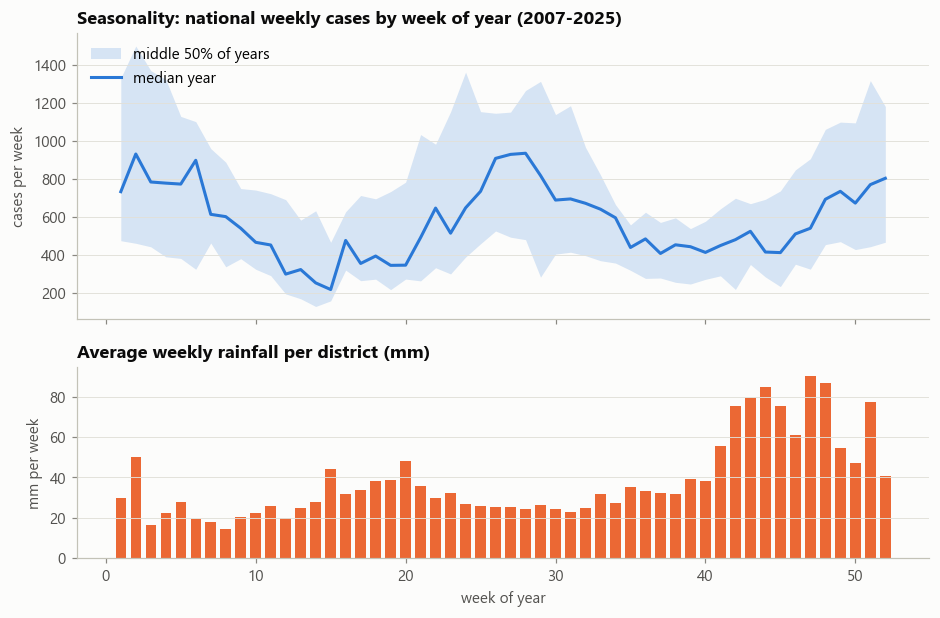

Peak median week: 28 | trough median week: 15


In [9]:
# Week 53 exists only in a few years, so it is left out of the typical-year profile.
cal = dengue.drop_duplicates("start_date").set_index("start_date")[["year", "week"]]
nat_df = cal.assign(cases=nat).dropna()
nat_df = nat_df[nat_df.year.between(2007, 2025) & (nat_df.week <= 52)]
q = nat_df.groupby("week").cases.quantile([.25, .5, .75]).unstack()

wx = data.load_weather_weekly()
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
ax.fill_between(q.index, q[.25], q[.75], color=viz.SERIES[0], alpha=0.18, lw=0, label="middle 50% of years")
ax.plot(q.index, q[.5], color=viz.SERIES[0], label="median year")
ax.set_title("Seasonality: national weekly cases by week of year (2007-2025)"); ax.set_ylabel("cases per week"); ax.legend(loc="upper left")
if wx is not None:
    wxm = wx.merge(dengue[["district", "start_date", "year", "week"]], on=["district", "start_date"])
    rain = wxm[wxm.year.between(2007, 2025) & (wxm.week <= 52)].groupby("week").rain_mm.mean()
    axes[1].bar(rain.index, rain.values, color=viz.SERIES[1], width=0.7)
    axes[1].set_title("Average weekly rainfall per district (mm)"); axes[1].set_ylabel("mm per week")
axes[1].set_xlabel("week of year")
viz.save(fig, "eda_seasonality"); plt.show()
print("Peak median week:", int(q[.5].idxmax()), "| trough median week:", int(q[.5].idxmin()))

## 5. Does weather lead dengue?
Mosquito breeding needs standing water; the virus also has incubation periods in the mosquito and the human.
So we expect rain to be correlated with cases **a few weeks later**. We check the Spearman correlation between
weekly cases and rainfall/humidity/temperature *k* weeks earlier, pooled over districts, after removing each
district's average level (so we don't just measure "big districts are rainy").

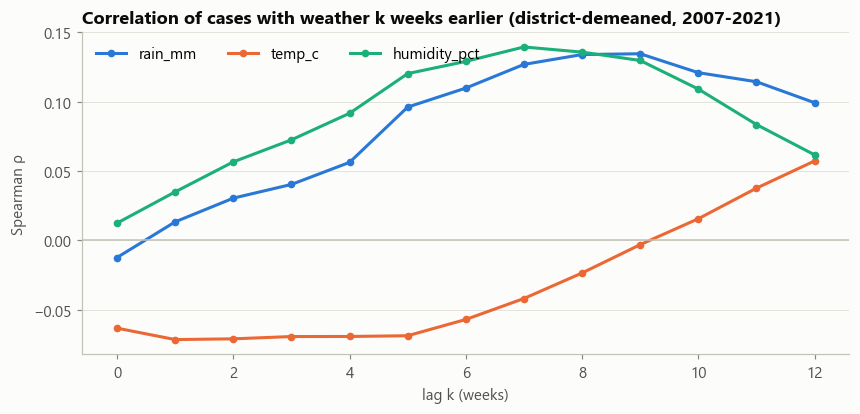

var  humidity_pct  rain_mm  temp_c
lag                               
0           0.012   -0.012  -0.063
1           0.035    0.013  -0.072
2           0.057    0.030  -0.071
3           0.072    0.040  -0.069
4           0.092    0.056  -0.069
5           0.120    0.096  -0.069
6           0.129    0.110  -0.057
7           0.139    0.127  -0.042
8           0.136    0.134  -0.024
9           0.130    0.135  -0.003
10          0.109    0.121   0.016
11          0.084    0.114   0.038
12          0.062    0.099   0.057
Weekly-aggregation coverage (days per week -> count): {7: 26701, 8: 26, 6: 26}


In [10]:
if wx is None:
    print("Weather unavailable - skipping.")
else:
    m = dengue.merge(wx, on=["district", "start_date"]).sort_values(["district", "start_date"])
    m = m[m.year <= config.TRAIN_END_YEAR]                         # look at training years only
    m["log_cases"] = np.log1p(m.cases)
    m["log_cases_dm"] = m.log_cases - m.groupby("district").log_cases.transform("mean")
    rows = []
    for var in config.WEATHER_VARS:
        dm = m[var] - m.groupby("district")[var].transform("mean")
        for k in range(0, 13):
            lagged = dm.groupby(m.district).shift(k)
            rows.append({"var": var, "lag": k, "rho": m.log_cases_dm.corr(lagged, method="spearman")})
    cc = pd.DataFrame(rows).pivot(index="lag", columns="var", values="rho")
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for i, var in enumerate(config.WEATHER_VARS):
        ax.plot(cc.index, cc[var], marker="o", ms=4, color=viz.SERIES[i], label=var)
    ax.axhline(0, color=viz.AXIS, lw=1)
    ax.set_title("Correlation of cases with weather k weeks earlier (district-demeaned, 2007-2021)")
    ax.set_xlabel("lag k (weeks)"); ax.set_ylabel("Spearman ρ"); ax.legend(ncol=3, loc="upper left")
    viz.save(fig, "eda_weather_lag_correlation"); plt.show()
    print(cc.round(3).to_string())
    print("Weekly-aggregation coverage (days per week -> count):", wx.n_days.value_counts().to_dict())

## 6. Persistence: the strongest signal
Dengue counts are highly autocorrelated week to week, which is why lagged cases will be the core features
and why a naive "same as last week" forecast is a strong baseline to beat.

In [11]:
ac = {k: dengue.groupby("district").cases.apply(lambda s: s.autocorr(k)).median() for k in [1, 2, 4, 8, 26, 52]}
print("Median (across districts) autocorrelation of weekly cases at lag k:")
print({k: round(v, 3) for k, v in ac.items()})
print("Share of zero-case district-weeks: %.1f%%" % (100 * (dengue.cases == 0).mean()))

Median (across districts) autocorrelation of weekly cases at lag k:
{1: 0.855, 2: 0.802, 4: 0.633, 8: 0.365, 26: 0.121, 52: 0.07}
Share of zero-case district-weeks: 12.2%


## 7. Planned chronological split

In [12]:
split = np.select([dengue.year <= config.TRAIN_END_YEAR, dengue.year == config.VAL_YEAR], ["train", "validation"], "test")
summary = dengue.assign(split=split).groupby("split").agg(rows=("cases", "size"), start=("start_date", "min"),
                                                          end=("end_date", "max"), mean_cases=("cases", "mean"))
summary.loc[["train", "validation", "test"]]

,rows,start,end,mean_cases
split,,,,
train,20384,2006-12-23,2021-12-31,29.826256
validation,1352,2022-01-01,2022-12-30,23.832957
test,5017,2022-12-31,2026-09-13,53.779948


## Key findings

* **Data obtained automatically and unaltered:** 26,753 weekly reports for **26 RDHS regions** from
  **23 Dec 2006 to 13 Sep 2026**, plus Open-Meteo weather for every region-week (no gaps).
* **Cleaning:** 3 spelling variants fixed, 2 date formats unified, and year/week rebuilt from dates
  (the source labels are inconsistent at New Year). **389 district-weeks (1.45%) flagged as missing reports**
  (northern regions 2007-2009, Monaragala 2020, the 10 Sep 2022 national gap); they are left as missing, not imputed.
* **Burden is concentrated:** Colombo (21.8%), Gampaha (12.8%) and Kandy (8.3%) account for ~43% of all
  2007-2025 cases, so absolute errors will be dominated by the Western Province.
* **Strong outbreaks / non-stationarity:** the record epidemic peaked at **10,590 cases in the week of 15 Jul 2017**
  (174,687 cases that year). 2019, 2023 and 2026 were also large outbreak years (2026 already has 94,033 cases by mid-September).
* **Seasonality:** the typical year peaks around **week 28 (mid-July, South-West monsoon)** with a second rise in
  Dec-Jan after the North-East monsoon rains (weeks 41-48), and is lowest around **week 15 (April)**, which motivates `week_sin/week_cos`.
* **Persistence is the strongest signal:** median lag-1 autocorrelation is **0.855** (lag-4: 0.63), so lagged cases
  will dominate, and the naive "same as last week" baseline will be hard to beat.
* **Weather leads cases by ~2 months:** after removing district averages, rainfall correlates most with cases
  **8-9 weeks later** (ρ ≈ 0.135) and humidity at **7 weeks** (ρ ≈ 0.139); at the 1-4 week lags in the brief the
  correlation is only 0.01-0.06. Weather is a weak but real, biologically plausible signal (breeding sites + incubation).
* **Split:** train = 2007-2021, validation = 2022, test = 31 Dec 2022 to 13 Sep 2026 (3.7 years). The test period
  is an *outbreak-heavy* period (mean 53.8 cases/region-week vs 29.8 in training and 23.8 in validation), a tough but realistic test.